# 02 · Supervised Fine-Tuning and LoRA: Teaching the Format, Inheriting the Mistakes

## Overview

| # | Notebook | Idea | What it fixes | What it leaves open |
|---|---|---|---|---|
| 01 | Pretraining | Next-token prediction on raw text | Knowledge: the model *can* add | Doesn't follow instructions |
| **02** | **SFT + LoRA** | **Imitate demonstrations** | **Follows the chat format** | **Copies demonstrators' mistakes; forgets** |
| 03 | Reward model + PPO | Learn a reward from preferences, optimise it | Can go beyond imitation | Reward hacking; four models; fragile |
| 04 | DPO family | Optimise preferences directly, no RL loop | Simple and stable | Offline: only re-weights existing behaviour |
| 05 | GRPO / RLVR | Online RL against a verifier | Verifiable gains, no value network | Sharpens, rarely expands; needs a capable start |
| 06 | Diffusion | Learn to denoise | Stable, high-quality generation | Matches data, not *goals*; slow sampling |
| 07 | Diffusion post-training | Fine-tune and reward-align a denoiser | Steer generation to a goal | Reward hacking again; still slow |
| 08 | Distillation | Few-step students | 10-100x faster sampling | Small denoisers don't scale |
| 09 | Diffusion transformers | Tokens + adaLN + flow matching | Scalable, flexible conditioning | Needs post-training too |
| 10 | Capstone | GRPO and DPO on a DiT; diffusion LMs | Unifies both threads | → the research frontier |

Notebook 01 ended with a model that **knows** how to add but scores **0%** when asked in a chat format.
The first fix, historically and in every modern pipeline, is **supervised fine-tuning (SFT)**, also called
instruction tuning: collect demonstrations of the behaviour you want and continue training on them.
FLAN ([Wei et al., 2021](https://arxiv.org/abs/2109.01652)) and T0 ([Sanh et al., 2021](https://arxiv.org/abs/2110.08207)) showed that fine-tuning on many tasks phrased as instructions
makes models follow *new* instructions; InstructGPT ([Ouyang et al., 2022](https://arxiv.org/abs/2203.02155)) made SFT on human-written
demonstrations the first of its three stages.

Our demonstrations are written by two kinds of simulated annotator, which is the important part:

* **careful** annotators (70%) are always right and usually answer in a full sentence;
* **sloppy** annotators (30%) are wrong 60% of the time (dropped carries, off-by-ten, off-by-one) and usually answer tersely.

So about 18% of the SFT data is wrong. Real demonstration data is never perfect, and this notebook measures
what SFT does with imperfect data.

## Learning objectives

1. Implement the SFT loss with prompt tokens masked out and explain why the mask is there.
2. Show that SFT fixes the format, and measure that it also copies the demonstrators' error rate, which greedy decoding hides.
3. Measure catastrophic forgetting, and how LoRA ([Hu et al., 2021](https://arxiv.org/abs/2106.09685)) trades some task fit for much less forgetting with ~4% of the trainable parameters.
4. Reproduce the "less is more" finding of LIMA ([Zhou et al., 2023](https://arxiv.org/abs/2305.11206)): a small clean dataset can match a large noisy one.

**Runtime:** about 3 minutes on a laptop CPU.

In [1]:
import sys, time, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
sys.path.insert(0, ".")
from ptlib import tasks, lm, align, metrics, set_seed
torch.set_num_threads(min(8, torch.get_num_threads()))
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
base = lm.get_pretrained()            # notebook 01's model (re-trained automatically if missing)
print(f"base model: {lm.n_params(base):,} parameters")

base model: 807,808 parameters


## 1. The demonstration data

In [2]:
demos = tasks.demonstrations(align.SFT_KW["n_demos"], seed=0)
df = pd.DataFrame(demos)
for d in demos[:4]:
    print(repr(d["prompt"] + d["response"]), "  <-", d["annotator"], "" if d["correct"] else "(WRONG)")
print()
print(f"{len(df)} demonstrations, {df.correct.mean():.1%} correct")
display(df.groupby(["annotator", "style"]).correct.agg(["mean", "count"]).round(3))

'Q: what is 49 plus 70?\nA: 19\n'   <- sloppy (WRONG)
'Q: add 31 and 23.\nA: 54\n'   <- sloppy 
'Q: what is 81 plus 44?\nA: the answer is 125.\n'   <- careful 
'Q: 26+51=?\nA: the answer is 77.\n'   <- careful 

3000 demonstrations, 81.8% correct


mean  count
annotator style                 
careful   sentence  1.000   1676
          terse     1.000    433
sloppy    sentence  0.419    179
          terse     0.378    712

Note the correlation built into the data, because it will matter in notebook 03: **terse answers are wrong
much more often than full sentences**, simply because sloppy annotators prefer to be terse. Nobody
designed the style to be informative about correctness, but in the data it is.

## 2. The SFT objective

SFT is the pretraining loss restricted to the **response** tokens:
$$\mathcal{L}_{\text{SFT}}(\theta) = -\,\mathbb{E}_{(x, y) \sim \mathcal{D}_{\text{demo}}} \sum_{t=1}^{|y|} \log \pi_\theta(y_t \mid x, y_{<t}).$$

The prompt $x$ is fed to the model but is not a prediction target: we want the model to learn *how to
answer*, not to model the distribution of user questions. `lm.pack` builds the batch and a mask that is 1
only on response tokens (including the newline that ends the answer, so the model also learns *when to stop*).

In [3]:
x, y, m = lm.pack([demos[0]["prompt"]], [demos[0]["response"]])
print("input :", repr(tasks.decode(x[0].tolist())))
print("target:", "".join(c if k else "·" for c, k in zip(tasks.decode(y[0].tolist()), m[0].tolist())).replace(chr(10), "⏎"))
print("        (· = not in the loss)")
print()
print(inspect.getsource(align.sft))

input : 'Q: what is 49 plus 70?\nA: 19'
target: ························ 19⏎
        (· = not in the loss)

def sft(model, data, epochs=3, batch=64, lr=5e-4, seed=0, log=True):
    """Next-token loss on response tokens only (prompt tokens are masked out)."""
    set_seed(seed)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.0)
    n_steps = epochs * math.ceil(len(data) / batch)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: 1 - s / n_steps)
    losses = []
    model.train()
    for ep in range(epochs):
        perm = np.random.permutation(len(data))
        for i in range(0, len(data), batch):
            b = [data[j] for j in perm[i:i + batch]]
            lp, m = lm.sequence_logprobs(model, [d["prompt"] for d in b], [d["response"] for d in b], per_token=True)
            loss = -lp.sum() / m.sum()
            opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(params, 1.0); opt.step()

## 3. Full fine-tuning

In [4]:
prose = tasks.prose_corpus()
sft_full = lm.get_pretrained(verbose=False)
t0 = time.time()
sft_losses = align.sft(sft_full, demos, epochs=align.SFT_KW["epochs"], lr=align.SFT_KW["lr"])
t_full = time.time() - t0
lm.save(sft_full, "sft_lm")                       # the reference model for notebooks 03-05

res = {"base (pretrained)": {**align.evaluate(base), "prose_loss": lm.corpus_loss(base, prose),
                             "completion_acc_2d": align.completion_accuracy(base, tasks.TEST_2D), "trainable": 0, "seconds": 0}}
res["SFT (full)"] = {**align.evaluate(sft_full), "prose_loss": lm.corpus_loss(sft_full, prose),
                     "completion_acc_2d": align.completion_accuracy(sft_full, tasks.TEST_2D),
                     "trainable": lm.n_params(sft_full), "seconds": t_full}
display(pd.DataFrame(res).T.round(3))
rng = np.random.default_rng(0)
for a, b in tasks.TEST_2D[:4]:
    p = tasks.make_prompt(a, b, rng=rng)
    print(repr(p), "->", repr(lm.generate(sft_full, [p], greedy=True)[0]))

epoch 1: loss 0.491
epoch 2: loss 0.131
epoch 3: loss 0.116


,greedy_acc,sampled_acc,well_formed,sentence_style,mean_len,prose_loss,completion_acc_2d,trainable,seconds
base (pretrained),0.000,0.000,0.000,0.000,20.022,0.335,0.912,0.0,0.000
SFT (full),0.998,0.775,0.995,0.598,13.545,3.020,0.038,807808.0,9.368


'Q: 39+79=?\nA:' -> ' the answer is 118.\n'
'Q: add 91 and 45.\nA:' -> ' the answer is 136.\n'
'Q: add 47 and 18.\nA:' -> ' the answer is 65.\n'
'Q: what is 21 plus 22?\nA:' -> ' the answer is 43.\n'


SFT fixes the format immediately: well-formed answers go from 0% to ~100%, and **greedy** accuracy is near
perfect. The **sampled** accuracy (temperature 1) is much lower and sits close to the demonstrators' own
correctness rate. Both numbers come from the same model. The difference is what each decoding rule reads
off the learned distribution:

* SFT is maximum likelihood, so the model learns the **demonstrators' distribution**: for each problem it puts most of its probability on the right answer and roughly the sloppy annotators' share on plausible wrong ones.
* Greedy decoding picks the mode and hides that mass. Sampling exposes it.

Sampling matters because chat models are usually sampled, and every RL method in this series learns from
samples. The cell below checks that the model also inherited the *correlation* between style and correctness.

In [5]:
P = align.train_prompts(3000, seed=11)
set_seed(0); R = lm.generate(sft_full, P)
samp = pd.DataFrame([dict(style=tasks.parse_response(r)[1] or "malformed",
                          correct=tasks.gold_reward(*tasks.a_b_from_prompt(p), r)) for p, r in zip(P, R)])
display(samp.groupby("style").correct.agg(["mean", "count"]).round(3))

,mean,count
style,,
malformed,0.000,29
sentence,0.886,1730
terse,0.566,1241


## 4. Catastrophic forgetting

What happened to everything else the model knew? The prose loss is the base model's loss on held-out
sentences from the toy grammar, text that never appears in the SFT data. Look back at the table in
section 3: full fine-tuning raises it many-fold. Three epochs on a few thousand chat transcripts
overwrite the general language model. Even the arithmetic is affected: the `completion_acc_2d` column asks
the pretraining-style question `a+b=`, and full SFT drops it from about 91% to a few percent. The skill now
survives only behind the chat format. InstructGPT
reported a version of this (an "alignment tax" on public NLP benchmarks) and added pretraining data back into
the RL stage to reduce it ([Ouyang et al., 2022](https://arxiv.org/abs/2203.02155)).

## 5. Parameter-efficient fine-tuning: LoRA

Adapters ([Houlsby et al., 2019](https://arxiv.org/abs/1902.00751)) and prefix tuning ([Li & Liang, 2021](https://arxiv.org/abs/2101.00190)) showed that you can adapt a frozen model by training
a small number of new parameters. **LoRA** ([Hu et al., 2021](https://arxiv.org/abs/2106.09685)) is the version that became standard. Each frozen
weight $W \in \mathbb{R}^{d_\text{out} \times d_\text{in}}$ gets a trainable low-rank update:
$$W' = W + \frac{\alpha}{r} B A, \qquad A \in \mathbb{R}^{r \times d_\text{in}},\; B \in \mathbb{R}^{d_\text{out} \times r},\; r \ll d.$$

$B$ starts at zero, so training starts exactly at the base model. After training, $BA$ can be **merged**
into $W$, so inference costs nothing extra. QLoRA ([Dettmers et al., 2023](https://arxiv.org/abs/2305.14314)) adds 4-bit quantisation of $W$, which
is how 65B-parameter models are fine-tuned on one GPU.

In [6]:
print(inspect.getsource(lm.LoRALinear))
for r in [1, 4, 16]:
    set_seed(0)
    mod = lm.add_lora(lm.get_pretrained(verbose=False), r=r, alpha=2 * r)
    t0 = time.time()
    align.sft(mod, demos, epochs=align.SFT_KW["epochs"], lr=3e-3, log=False)
    res[f"SFT (LoRA r={r})"] = {**align.evaluate(mod), "prose_loss": lm.corpus_loss(mod, prose),
                                "completion_acc_2d": align.completion_accuracy(mod, tasks.TEST_2D),
                                "trainable": lm.n_params(mod, trainable_only=True), "seconds": time.time() - t0}
    if r == 4:
        lora4 = mod
table = pd.DataFrame(res).T
display(table[["trainable", "greedy_acc", "sampled_acc", "well_formed", "prose_loss", "completion_acc_2d", "seconds"]].round(3))

class LoRALinear(nn.Module):
    """y = W x + (alpha / r) * B A x, with W frozen, A random and B zero at initialisation (Hu et al., 2021)."""

    def __init__(self, base: nn.Linear, r=4, alpha=8):
        super().__init__()
        self.base, self.r, self.scale = base, r, alpha / r
        for p in self.base.parameters():
            p.requires_grad_(False)
        self.A = nn.Parameter(torch.randn(r, base.in_features) / math.sqrt(base.in_features))
        self.B = nn.Parameter(torch.zeros(base.out_features, r))

    def forward(self, x):
        return self.base(x) + self.scale * (x @ self.A.T) @ self.B.T



,trainable,greedy_acc,sampled_acc,well_formed,prose_loss,completion_acc_2d,seconds
base (pretrained),0.0,0.000,0.000,0.000,0.335,0.912,0.000
SFT (full),807808.0,0.998,0.775,0.995,3.020,0.038,9.368
SFT (LoRA r=1),8192.0,0.828,0.472,0.942,1.718,0.498,10.145
SFT (LoRA r=4),32768.0,0.998,0.758,0.982,2.104,0.315,12.902
SFT (LoRA r=16),131072.0,1.000,0.785,0.995,2.935,0.082,13.847


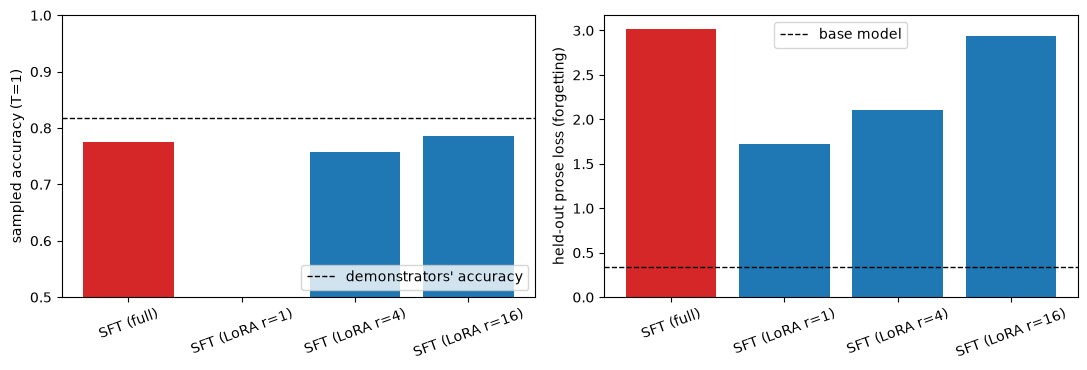

outputs identical after merging B·A into W: True | parameters after merge: 807,808


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
t = table.drop("base (pretrained)")
axes[0].bar(t.index, t.sampled_acc, color=["tab:red"] + ["tab:blue"] * 3)
axes[0].axhline(df.correct.mean(), ls="--", c="k", lw=1, label="demonstrators' accuracy")
axes[0].set_ylabel("sampled accuracy (T=1)"); axes[0].set_ylim(0.5, 1); axes[0].legend(loc="lower right")
axes[0].tick_params(axis="x", rotation=20)
axes[1].bar(t.index, t.prose_loss, color=["tab:red"] + ["tab:blue"] * 3)
axes[1].axhline(table.loc["base (pretrained)", "prose_loss"], ls="--", c="k", lw=1, label="base model")
axes[1].set_ylabel("held-out prose loss (forgetting)"); axes[1].legend(); axes[1].tick_params(axis="x", rotation=20)
fig.tight_layout(); plt.show()

# merging: the adapted model and the merged plain GPT give identical outputs
probe = [tasks.make_prompt(a, b) for a, b in tasks.TEST_2D[:50]]
before = lm.generate(lora4, probe, greedy=True)
merged = lm.merge_lora(lora4)
print("outputs identical after merging B·A into W:", before == lm.generate(merged, probe, greedy=True),
      "| parameters after merge:", f"{lm.n_params(merged):,}")

**Reading the LoRA comparison.** The rank $r$ sets a trade-off, and the table shows both ends of it:

* **r = 4** (about 4% of the parameters) matches full fine-tuning on the task, with the same greedy and similar sampled accuracy. It forgets noticeably less: lower prose loss, and much more of the `a+b=` skill retained.
* **r = 1** forgets least, but it also *learns* least. Its accuracy falls short of full fine-tuning.
* **r = 16** fits the task as well as full fine-tuning and forgets almost as much.

This is the empirical finding of [Biderman et al., 2024](https://arxiv.org/abs/2405.09673), "LoRA learns less and forgets less": a low-rank update cannot
move the model as far, in either direction. No method improves the *sampled* accuracy much beyond the
demonstrators. That ceiling comes from the data, not the optimiser.

## 6. Less is more: data quality beats quantity

LIMA ([Zhou et al., 2023](https://arxiv.org/abs/2305.11206)) fine-tuned a 65B model on just 1,000 carefully curated examples. It argued that
almost all knowledge is learned in pretraining, so SFT only needs to teach the *format*: the "superficial
alignment hypothesis". We can test the claim directly: 300 or 1,000 demonstrations from **careful annotators
only**, against the 3,000 noisy ones.

In [8]:
for n in [300, 1000]:
    sft_clean = lm.get_pretrained(verbose=False)
    align.sft(sft_clean, tasks.demonstrations(n, p_sloppy=0.0, seed=3), epochs=6, lr=5e-4, log=False)
    res[f"SFT ({n} clean demos)"] = {**align.evaluate(sft_clean), "prose_loss": lm.corpus_loss(sft_clean, prose),
                                     "completion_acc_2d": align.completion_accuracy(sft_clean, tasks.TEST_2D),
                                     "trainable": lm.n_params(sft_clean), "seconds": np.nan}
display(pd.DataFrame(res).T.loc[["SFT (full)", "SFT (300 clean demos)", "SFT (1000 clean demos)"],
                                ["greedy_acc", "sampled_acc", "well_formed", "sentence_style"]].round(3))

,greedy_acc,sampled_acc,well_formed,sentence_style
SFT (full),0.998,0.775,0.995,0.598
SFT (300 clean demos),0.955,0.672,0.975,0.780
SFT (1000 clean demos),1.000,0.930,0.995,0.795


A third of the data, none of it wrong, gives much higher sampled accuracy than the 3,000 noisy
demonstrations. Quality beats quantity, but only down to a point. With 300 examples our 0.8M-parameter model
does *worse* than with the noisy set: it has not seen enough examples to pin down the format. LIMA's 1,000
examples were enough for a 65B-parameter model, whose pretraining had done far more of the work. The
superficial-alignment hypothesis is a statement about strong base models.

That raises the question for the next notebook. **Producing clean demonstrations is expensive, and for
open-ended tasks there may be no "correct" demonstration at all.** It is usually much easier for a person
to say which of two answers is *better* than to write the best answer. Notebook 03 uses exactly that signal.

## 7. Scorecard

In [9]:
rows = [dict(model=k, family="lm", **{c: v[c] for c in ["greedy_acc", "sampled_acc", "well_formed", "sentence_style",
                                                         "mean_len", "prose_loss", "completion_acc_2d", "trainable"]})
        for k, v in res.items() if k != "base (pretrained)"]
metrics.append_rows(rows, "02_sft")
display(metrics.load_scorecard().query("family == 'lm'")[["notebook", "model", "greedy_acc", "sampled_acc", "well_formed", "prose_loss"]].round(3))

,notebook,model,greedy_acc,sampled_acc,well_formed,prose_loss
0,01_pretraining,base (pretrained),0.000,0.000,0.000,NaN
1,03_rlhf_ppo,"PPO vs RM-small, beta=0.05",1.000,0.895,0.998,NaN
2,03_rlhf_ppo,"PPO vs RM-large, beta=0.05",0.732,0.635,1.000,NaN
3,03_rlhf_ppo,"PPO vs RM-large, beta=0",0.005,0.005,0.988,NaN
4,03_rlhf_ppo,"PPO vs verifier, beta=0.05",1.000,0.948,0.985,NaN
7,02_sft,SFT (full),0.998,0.775,0.995,3.020
8,02_sft,SFT (LoRA r=1),0.828,0.472,0.942,1.718
9,02_sft,SFT (LoRA r=4),0.998,0.758,0.982,2.104
10,02_sft,SFT (LoRA r=16),1.000,0.785,0.995,2.935
11,02_sft,SFT (300 clean demos),0.955,0.672,0.975,1.842


## Challenge Problem 1: What if the prompt tokens are not masked?

Train a copy of the base model on the same demonstrations, but with the loss on **every** token (prompt and
response). Hint: call `lm.sequence_logprobs(model, [""] * len(b), [d["prompt"] + d["response"] for d in b], per_token=True)`,
which treats the whole transcript as a "response". Compare sampled accuracy and prose loss with masked SFT.
Which one spends more capacity on modelling *questions*?

In [10]:
# Start your code here

### Challenge Problem 1 Solution

In [11]:
set_seed(0)
nomask = lm.get_pretrained(verbose=False)
opt = torch.optim.AdamW(nomask.parameters(), lr=5e-4)
nomask.train()
for ep in range(3):
    perm = np.random.permutation(len(demos))
    for i in range(0, len(demos), 64):
        b = [demos[j] for j in perm[i:i + 64]]
        lp, mk = lm.sequence_logprobs(nomask, [""] * len(b), [d["prompt"] + d["response"] for d in b], per_token=True)
        loss = -lp.sum() / mk.sum()
        opt.zero_grad(); loss.backward(); opt.step()
r = align.evaluate(nomask)
print("no prompt mask:", {k: round(v, 3) for k, v in r.items()}, "| prose loss", round(lm.corpus_loss(nomask, prose), 3))
print("masked SFT    :", {k: round(res['SFT (full)'][k], 3) for k in r})
# With a toy prompt distribution the difference is small: the prompts are easy to model. In real
# chat data, prompts are long and diverse, and modelling them wastes capacity and can teach the model to
# generate user turns, which is why SFT libraries mask the prompt by default.

no prompt mask: {'greedy_acc': 0.98, 'sampled_acc': 0.767, 'well_formed': 0.983, 'sentence_style': 0.672, 'mean_len': 14.822} | prose loss 3.068
masked SFT    : {'greedy_acc': 0.998, 'sampled_acc': 0.775, 'well_formed': 0.995, 'sentence_style': 0.598, 'mean_len': 13.545}


## Challenge Problem 2: Filter with the verifier

Our world has a verifier, so we can *filter* the noisy demonstrations, keeping only the correct ones, before SFT.
Do it, train, and compare the sampled accuracy with the unfiltered SFT model. Then explain in one sentence why this
fix is not available for most real tasks, and what kind of signal could replace the verifier.

In [12]:
# Start your code here

### Challenge Problem 2 Solution

In [13]:
filtered = [d for d in demos if tasks.gold_reward(d["a"], d["b"], d["response"]) == 1.0]
m_f = lm.get_pretrained(verbose=False)
align.sft(m_f, filtered, epochs=3, lr=5e-4, log=False)
print(f"kept {len(filtered)}/{len(demos)} demonstrations")
print("filtered SFT sampled accuracy:", round(align.evaluate(m_f)["sampled_acc"], 3),
      "| unfiltered:", round(res["SFT (full)"]["sampled_acc"], 3))
# For open-ended tasks (writing, advice, code style) there is no programmatic verifier. What people *can*
# provide cheaply is a comparison: 'answer A is better than answer B'. Notebook 03 learns a reward from those.

kept 2453/3000 demonstrations
filtered SFT sampled accuracy: 0.943 | unfiltered: 0.775


## Final summary

* SFT is the pretraining loss restricted to response tokens. A few thousand demonstrations take the chat-format accuracy from 0% to ~100% (greedy).
* SFT learns the **demonstrators' distribution**, mistakes included. Sampled accuracy sits at the demonstrators' accuracy, and the model also inherits incidental correlations, such as terse answers being wrong more often.
* Full fine-tuning causes large forgetting of unrelated text. LoRA trains a few percent of the parameters, matches task performance and forgets much less.
* Clean data beats more data. But clean demonstrations are expensive, and for many tasks impossible, which motivates learning from **comparisons** instead (notebook 03).

## References

* Jason Wei, Maarten Bosma, Vincent Y. Zhao et al. (2021). **Finetuned Language Models Are Zero-Shot Learners**. arXiv:2109.01652. [arxiv.org/abs/2109.01652](https://arxiv.org/abs/2109.01652)
* Victor Sanh, Albert Webson, Colin Raffel et al. (2021). **Multitask Prompted Training Enables Zero-Shot Task Generalization**. arXiv:2110.08207. [arxiv.org/abs/2110.08207](https://arxiv.org/abs/2110.08207)
* Long Ouyang, Jeff Wu, Xu Jiang et al. (2022). **Training language models to follow instructions with human feedback**. arXiv:2203.02155. [arxiv.org/abs/2203.02155](https://arxiv.org/abs/2203.02155)
* Neil Houlsby, Andrei Giurgiu, Stanislaw Jastrzebski et al. (2019). **Parameter-Efficient Transfer Learning for NLP**. arXiv:1902.00751. [arxiv.org/abs/1902.00751](https://arxiv.org/abs/1902.00751)
* Xiang Lisa Li, Percy Liang (2021). **Prefix-Tuning: Optimizing Continuous Prompts for Generation**. arXiv:2101.00190. [arxiv.org/abs/2101.00190](https://arxiv.org/abs/2101.00190)
* Edward J. Hu, Yelong Shen, Phillip Wallis et al. (2021). **LoRA: Low-Rank Adaptation of Large Language Models**. arXiv:2106.09685. [arxiv.org/abs/2106.09685](https://arxiv.org/abs/2106.09685)
* Tim Dettmers, Artidoro Pagnoni, Ari Holtzman et al. (2023). **QLoRA: Efficient Finetuning of Quantized LLMs**. arXiv:2305.14314. [arxiv.org/abs/2305.14314](https://arxiv.org/abs/2305.14314)
* Chunting Zhou, Pengfei Liu, Puxin Xu et al. (2023). **LIMA: Less Is More for Alignment**. arXiv:2305.11206. [arxiv.org/abs/2305.11206](https://arxiv.org/abs/2305.11206)
* Dan Biderman, Jacob Portes, Jose Javier Gonzalez Ortiz et al. (2024). **LoRA Learns Less and Forgets Less**. arXiv:2405.09673. [arxiv.org/abs/2405.09673](https://arxiv.org/abs/2405.09673)

The full, verified list for the series is in [`research_papers/README.md`](research_papers/README.md).